# **Image class distribution**

In [21]:
import pathlib
from pathlib import Path
import cv2

In [22]:
#paths
cat_train=Path("/home/omar/Projects/pcv/data/splitted-data/train/Cat")
cat_val=Path("/home/omar/Projects/pcv/data/splitted-data/val/Cat")
dog_train=Path("/home/omar/Projects/pcv/data/splitted-data/train/Dog")
dog_val=Path("/home/omar/Projects/pcv/data/splitted-data/val/Dog")

In [23]:
def count_classes(*args: pathlib.PosixPath)->dict:
    counts={}
    for path in args:
        folder_name = f"{path.parent.name}_{path.name}" 
        file_count =len(list(path.iterdir())) 
        
        counts[folder_name] = file_count
        
    return counts
    
count_classes(cat_train,cat_val,dog_train,dog_val)

{'train_Cat': 9999, 'val_Cat': 2500, 'train_Dog': 9999, 'val_Dog': 2500}

the data is balanced

# **Image Dimensions**

In [28]:
def get_simple_dimensions(folder_path, sample_size=500):
    widths = []
    heights = []
    
    image_paths = list(folder_path.iterdir())[:sample_size]
    
    for img_path in image_paths:
        img = cv2.imread(str(img_path))
        if img is not None:
            heights.append(img.shape[0])  
            widths.append(img.shape[1])   
            
    return widths, heights

w, h = get_simple_dimensions(cat_train)

print("first 5 widths:", w[:5])
print("first 5 hights:", h[:5])

first 5 widths: [375, 121, 500, 320, 500]
first 5 hights: [500, 140, 393, 319, 335]


# **visual inspection**

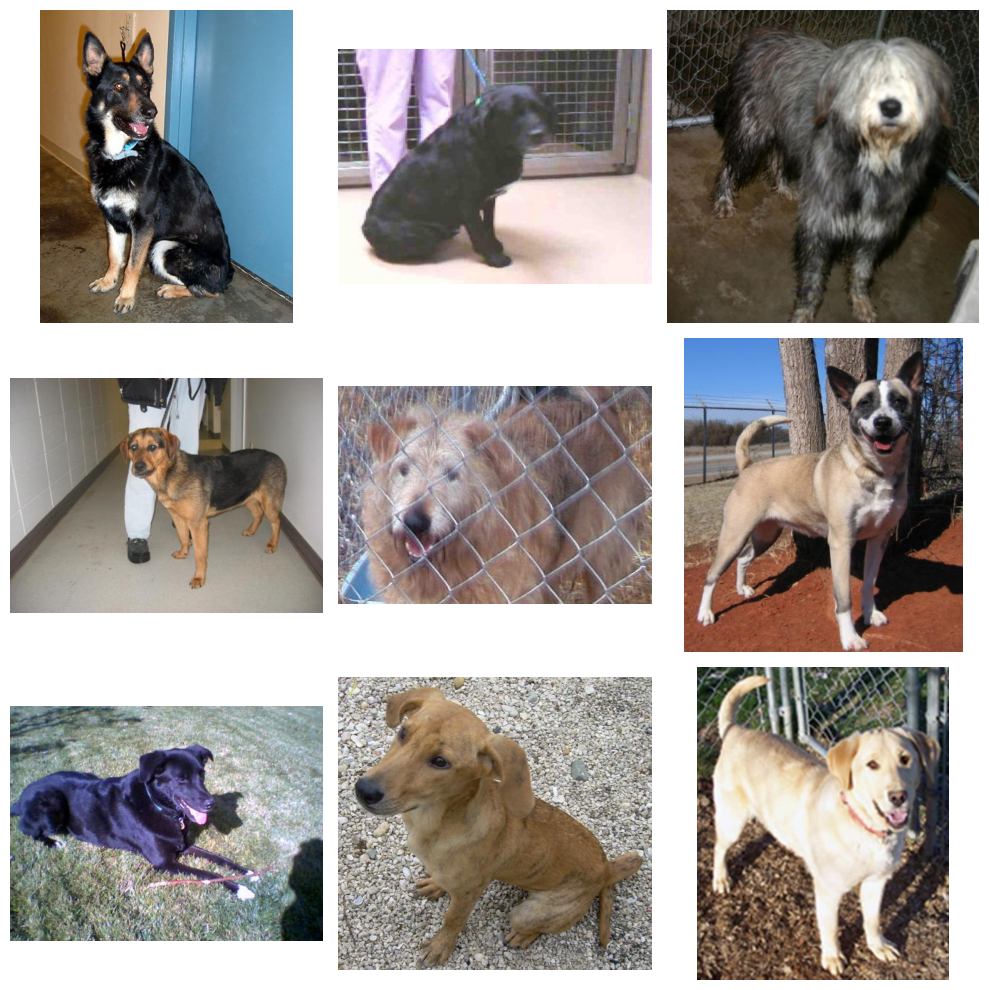

In [32]:
import random
import matplotlib.pyplot as plt

def plot_random_images(folder_path, num_images=9):
    all_paths = list(folder_path.iterdir())
    sampled_paths = random.sample(all_paths, num_images)
    
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    
    for i, img_path in enumerate(sampled_paths):
        img = cv2.imread(str(img_path))
        
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            row = i // 3
            col = i % 3
            ax = axes[row, col]
            
            ax.imshow(img_rgb)
            ax.axis('off')
            
    plt.tight_layout()
    plt.show()

plot_random_images(dog_train)

# **corruption check**

In [33]:
def remove_corrupt_images(folder_path: Path) -> int:
    corrupt_count = 0
    
    for img_path in folder_path.iterdir():
        if img_path.is_file():
            img = cv2.imread(str(img_path))
            
            if img is None:
                print(f"صورة تالفة تم حذفها: {img_path.name}")
                img_path.unlink()  
                corrupt_count += 1
                
    print(f"تم فحص مجلد ({folder_path.name}). إجمالي الصور التالفة المحذوفة: {corrupt_count}")
    return corrupt_count

In [34]:
print("جاري فحص مجلدات التدريب...")
remove_corrupt_images(cat_train)
remove_corrupt_images(dog_train)

print("جاري فحص مجلدات الاختبار...")
remove_corrupt_images(cat_val)
remove_corrupt_images(dog_val)

جاري فحص مجلدات التدريب...


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


صورة تالفة تم حذفها: 10404.jpg


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


تم فحص مجلد (Cat). إجمالي الصور التالفة المحذوفة: 1


...

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


تم فحص مجلد (Cat). إجمالي الصور التالفة المحذوفة: 0


Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9


تم فحص مجلد (Dog). إجمالي الصور التالفة المحذوفة: 0


0